In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

In [2]:
class_tab = pd.read_csv('Pv_loc_table.csv')
class_tab.head()

,Sample,PvP01_01_v1 4052,PvP01_01_v1 41174,PvP01_01_v1 41198,PvP01_01_v1 41246,PvP01_01_v1 41251,PvP01_01_v1 41284,PvP01_01_v1 41343,PvP01_01_v1 41367,PvP01_01_v1 41369,...,PvP01_API_v1 18211,PvP01_API_v1 18390,PvP01_API_v1 20013,PvP01_API_v1 23818,PvP01_API_v1 23912,PvP01_API_v1 26449,PvP01_MIT_v1 2036,PvP01_MIT_v1 4510,PvP01_MIT_v1 4640,Continent
0,PJ0277-C,0.0,1.0,1.0,1.0,0.0,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,1.0,1.0,1.0,1.0,SE_Asia
1,PJ0273-C,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,SE_Asia
2,PD0168-C,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,1.0,...,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,SE_Asia
3,PJ0167-C,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,1.0,...,0.0,0.0,0.0,0.0,1.0,1.0,1.0,1.0,1.0,SE_Asia
4,Thailand_VKTS_36,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,SE_Asia


In [3]:
class_tab = class_tab.set_index('Sample') 

In [4]:
data_target = class_tab.loc[:,'Continent']
                            
data_predictors = class_tab.loc[:,class_tab.columns!='Continent']

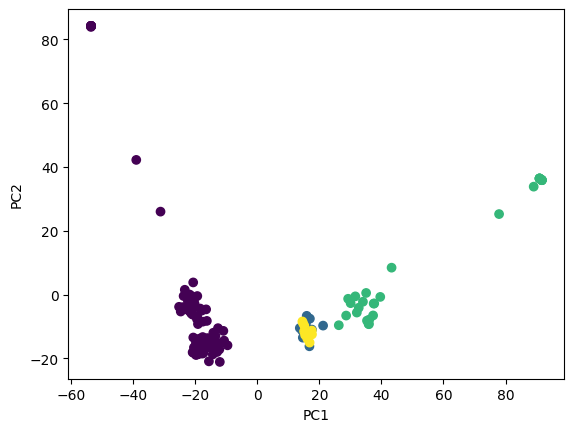

In [5]:
from sklearn.decomposition import PCA

# Perform PCA
pca = PCA(n_components = 10)
X_pca = pca.fit_transform(data_predictors)

# Plot
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=pd.factorize(data_target)[0])
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.show()

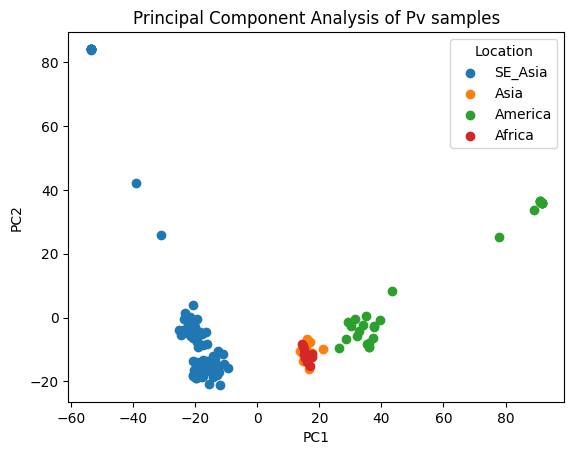

In [7]:
for continent in data_target.unique():
    mask = data_target == continent
    plt.scatter(X_pca[mask, 0], X_pca[mask, 1], label=continent)

plt.title("Principal Component Analysis of Pv samples")
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.legend(title='Location')
plt.savefig('PVCA.PNG')

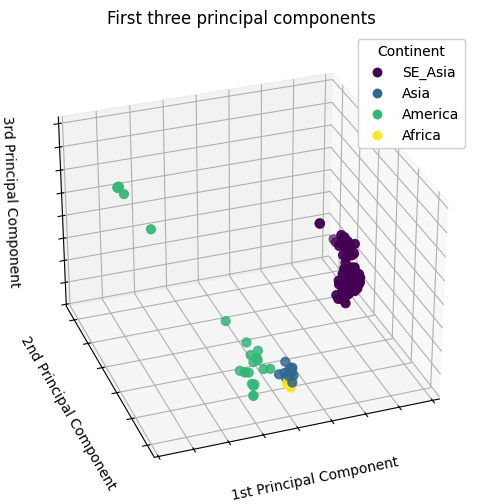

In [10]:
target_codes, target_labels = pd.factorize(data_target)

fig = plt.figure(1, figsize=(8, 6))
ax = fig.add_subplot(111, projection="3d", elev=-150, azim=110)

scatter = ax.scatter(
    X_pca[:, 0],
    X_pca [:, 1],
    X_pca [:, 2],
    c=target_codes,
    s=40,
)

ax.set(
    title="First three principal components",
    xlabel="1st Principal Component",
    ylabel="2nd Principal Component",
    zlabel="3rd Principal Component",
)
ax.xaxis.set_ticklabels([])
ax.yaxis.set_ticklabels([])
ax.zaxis.set_ticklabels([])

# Add a legend
legend1 = ax.legend(
    scatter.legend_elements()[0],
    target_labels.tolist(),
    loc="upper right",
    title="Continent",
)
ax.add_artist(legend1)

plt.show()

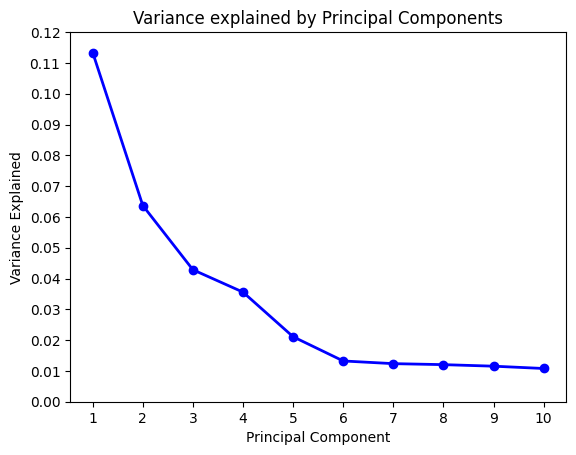

In [14]:
PC_values = np.arange(pca.n_components_) + 1
plt.plot(PC_values, pca.explained_variance_ratio_, 'o-', linewidth=2, color='blue')
plt.xticks(range(1,11))
plt.yticks([0, 0.01, 0.02, 0.03, 0.04, 0.05, 0.06, 0.07, 0.08, 0.09, 0.1, 0.11, 0.12])
plt.title('Variance explained by Principal Components')
plt.xlabel('Principal Component')
plt.ylabel('Variance Explained')
plt.savefig('Location_Scree.png')

In [8]:
loadings = pd.DataFrame(pca.components_[0], columns=['PC1'], index=data_predictors.columns)

loadings = loadings["PC1"].abs().sort_values(ascending=False)

loadings = pd.DataFrame(loadings)

In [36]:
loadings.to_csv('PCA_top_loadings.csv')